# 03 · Promotion effects and A/B tests

**Part A – Promotions.** Each of the 12 promotions is measured against a modelled counterfactual (trend + weekday +
seasonality + other known events), on the series it targeted, for **revenue, units and gross profit**. We also measure
pull-forward around Black Friday and the effect on the rest of the store (halo vs cannibalisation).

**Part B – A/B tests.** Two user-randomised experiments: a one-page checkout (AB1) and a social-proof badge (AB2).
For each: validity checks (sample-ratio mismatch, covariate balance, unaffected upstream steps), the pre-registered
primary metric with a variance estimate that respects the randomisation unit, guardrails, heterogeneity with
multiple-testing correction, a peeking analysis and power.

In [1]:
import sys, warnings
sys.path.insert(0, "../src"); sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from shopstats import *
set_style()
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 60)
try:
    display
except NameError:
    display = print

O = load_orders()
I = pd.read_parquet(DATA / "order_items.parquet")
U = pd.read_parquet(DATA / "users.parquet")
EV, PR = load_events()
AB = pd.read_csv(DATA / "ab_tests.csv")
S = load_sessions(["session_id", "user_id", "session_start", "channel", "device", "country", "is_new_user",
                   "is_loyalty_member", "ab_test", "ab_variant"] + FLAGS)
CATS = list(I["category"].cat.categories)

# Part A · Promotions
## A1. Method
`log(daily series) = trend + weekday + 3 annual harmonics + one dummy per promotion + pre/post Black Friday windows +
dummies for the known incidents`. A promotion's coefficient `b` gives the lift `exp(b) − 1`; incremental dollars are
`Σ actual × (1 − exp(−b))` over the promotion days. Standard errors: the larger of Newey–West (7 lags) and classical
(short dummies make robust errors over-confident). P-values are BH-adjusted across all promotion tests.

In [2]:
I["day"] = O["day"].values[I["order_id"].values - 1]
I["rev"] = I["unit_price_paid"] * I["quantity"]
I["profit"] = (I["unit_price_paid"] - I["unit_cost"]) * I["quantity"]
dc = I.groupby(["day", "category"], observed=True).agg(revenue=("rev", "sum"), profit=("profit", "sum"), units=("quantity", "sum")).unstack()
dc = dc.reindex(range(D))

ship = O.groupby("day")["shipping_fee"].sum().reindex(range(D)).fillna(0).values

def series(cats, metric):
    y = dc[metric][cats].sum(axis=1).values
    if metric == "profit" and len(cats) == len(CATS):
        y = y + ship            # store-wide profit includes shipping fees collected (free-shipping promos give them up)
    return y

def design():
    X = pd.DataFrame(index=np.arange(D))
    X["trend"] = np.arange(D) / 365.25
    for k in range(1, 7):
        X[f"dow{k}"] = (DAYS.dayofweek == k).astype(float)
    for k in (1, 2, 3):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * DAYS.dayofyear / 365.25)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * DAYS.dayofyear / 365.25)
    for _, p in PR.iterrows():
        X[p.promo_id] = window(p.start_date, p.end_date).astype(float)
    pre, post = np.zeros(D), np.zeros(D)
    for _, p in PR[PR["type"].eq("sitewide % off")].iterrows():
        a, b = day_index(p.start_date), day_index(p.end_date)
        pre[max(a - 7, 0):a] = 1; post[b + 1:b + 8] = 1
    X["bf_pre7"], X["bf_post7"] = pre, post
    for _, e in EV.iterrows():
        if e.type not in ("experiment", "seasonality") and e.event_id not in ("E02", "E05", "E13"):
            X[e.event_id] = window(e.start_date, e.end_date).astype(float)
    return sm.add_constant(X)

X = design()

def fit(y):
    ok = y > 0          # a 25% discount on thin-margin Electronics makes profit negative on Black Friday days: drop those days
    Xv = X.loc[ok, X.loc[ok].abs().sum() > 0]
    yy = np.log(y[ok])
    m, m0 = sm.OLS(yy, Xv).fit(cov_type="HAC", cov_kwds={"maxlags": 7}), sm.OLS(yy, Xv).fit()
    return m.params.reindex(X.columns), np.maximum(m.bse, m0.bse).reindex(X.columns)

def effect(y, term):
    b, se = fit(y)
    b_, s_ = b[term], se[term]
    days = X[term].values.astype(bool) & (y > 0)
    inc = lambda bb: float(np.sum(y[days] * (1 - np.exp(-bb))))
    return dict(lift=np.exp(b_) - 1, lo=np.exp(b_ - 1.96 * s_) - 1, hi=np.exp(b_ + 1.96 * s_) - 1,
                p=2 * stats.norm.sf(abs(b_ / s_)), inc=inc(b_), inc_lo=inc(b_ - 1.96 * s_), inc_hi=inc(b_ + 1.96 * s_))

scope = {}
for _, p in PR.iterrows():
    scope[p.promo_id] = CATS if p.categories == "All" else [c.strip() for c in p.categories.split(";")]

rows = []
for _, p in PR.iterrows():
    cats = scope[p.promo_id]
    rest = [c for c in CATS if c not in cats]
    r = dict(promo_id=p.promo_id, name=p["name"], type=p["type"], scope=p.categories, discount=p.discount_pct,
             days=int(X[p.promo_id].sum()))
    for metric in ["revenue", "units", "profit"]:
        e = effect(series(cats, metric), p.promo_id)
        for k, v in e.items():
            r[f"{metric}_{k}"] = v
    if rest:
        e = effect(series(rest, "revenue"), p.promo_id)
        r["rest_lift"], r["rest_p"] = e["lift"], e["p"]
    e = effect(series(CATS, "profit"), p.promo_id)          # whole store, incl. halo on other categories and shipping fees
    for k, v in e.items():
        r[f"store_profit_{k}"] = v
    rows.append(r)
promo = pd.DataFrame(rows)
pcols = ["revenue_p", "units_p", "profit_p", "store_profit_p"]
adj = bh(promo[pcols].values.ravel()).reshape(len(promo), len(pcols))
for i, c in enumerate(pcols):
    promo[c + "_adj"] = adj[:, i]

def verdict(r):
    if r.store_profit_p_adj < 0.05:
        return "adds profit store-wide" if r.store_profit_lift > 0 else "costs profit store-wide"
    if r.revenue_p_adj < 0.05:
        return f"revenue {'up' if r.revenue_lift > 0 else 'down'}, no significant store-wide profit effect"
    return "no significant revenue or store-wide profit effect"
promo["verdict"] = promo.apply(verdict, axis=1)
promo.to_csv(OUT / "promo_results.csv", index=False)

show = pd.DataFrame({
    "promotion": promo["promo_id"] + " " + promo["name"],
    "scope": promo["scope"], "disc.": promo["discount"].map("{:.0%}".format), "days": promo["days"],
    "revenue lift (95% CI)": promo.apply(lambda r: f"{r.revenue_lift:+.0%} [{r.revenue_lo:+.0%}, {r.revenue_hi:+.0%}] {stars(r.revenue_p_adj)}", axis=1),
    "units lift": promo.apply(lambda r: f"{r.units_lift:+.0%} {stars(r.units_p_adj)}", axis=1),
    "profit lift (95% CI)": promo.apply(lambda r: f"{r.profit_lift:+.0%} [{r.profit_lo:+.0%}, {r.profit_hi:+.0%}] {stars(r.profit_p_adj)}", axis=1),
    "rest of store revenue": promo.apply(lambda r: "" if pd.isna(r.rest_lift) else f"{r.rest_lift:+.0%} {stars(r.rest_p)}", axis=1),
    "STORE-WIDE profit lift (95% CI)": promo.apply(lambda r: f"{r.store_profit_lift:+.0%} [{r.store_profit_lo:+.0%}, {r.store_profit_hi:+.0%}] {stars(r.store_profit_p_adj)}", axis=1),
    "store-wide incr. profit $": promo["store_profit_inc"].map("{:+,.0f}".format),
    "verdict": promo["verdict"]})
print("Revenue / units / profit lift are measured on the promoted categories ('scope'); the last columns on the whole store.")
print("*** p<.001 ** p<.01 * p<.05 ns (BH-adjusted across the 48 tests)")
display(show)

Revenue / units / profit lift are measured on the promoted categories ('scope'); the last columns on the whole store.
*** p<.001 ** p<.01 * p<.05 ns (BH-adjusted across the 48 tests)


,promotion,scope,disc.,days,revenue lift (95% CI),units lift,profit lift (95% CI),rest of store revenue,STORE-WIDE profit lift (95% CI),store-wide incr. profit $,verdict
0,P01 Black Friday / Cyber Week 2024,All,25%,4,"+175% [+159%, +193%] ***",+277% ***,"+17% [+10%, +23%] ***",,"+17% [+10%, +23%] ***","+41,317",adds profit store-wide
1,P02 Spring Sale 2025,Fashion; Home & Garden,15%,7,"+30% [+23%, +37%] ***",+49% ***,"+3% [-2%, +9%] ns",+35% ***,"+23% [+18%, +28%] ***","+95,289",adds profit store-wide
2,P03 Summer Clearance 2025,Fashion,30%,11,"+2% [-3%, +7%] ns",+46% ***,"-39% [-42%, -35%] ***",+17% ***,"+5% [-1%, +10%] ns","+30,776",no significant revenue or store-wide profit effect
3,P04 Back to School 2025,Electronics; Books & Media,10%,14,"+7% [+1%, +12%] *",+18% ***,"-35% [-38%, -31%] ***",+12% ***,"-3% [-7%, -0%] *","-29,652",costs profit store-wide
4,P05 LOYAL20 Member Flash Sale,All,20%,4,"+20% [+13%, +28%] ***",+25% ***,"+7% [+2%, +14%] *",,"+7% [+2%, +14%] *","+20,527",adds profit store-wide
5,P06 Free Shipping Weekend (Oct 2025),All,0%,3,"+17% [+9%, +25%] ***",+12% ***,"+11% [+4%, +18%] **",,"+11% [+4%, +18%] **","+24,111",adds profit store-wide
6,P07 Black Friday / Cyber Week 2025,All,25%,4,"+179% [+163%, +197%] ***",+272% ***,"+31% [+24%, +39%] ***",,"+31% [+24%, +39%] ***","+98,376",adds profit store-wide
7,P08 Beauty BOGO Week,Beauty,50%,7,"-14% [-20%, -7%] ***",+71% ***,"-73% [-75%, -71%] ***",+2% ns,"-4% [-9%, -0%] ns","-18,974","revenue down, no significant store-wide profit effect"
8,P09 Spring Sale 2026,Fashion; Home & Garden,15%,7,"+34% [+27%, +41%] ***",+58% ***,"+7% [+1%, +13%] *",+41% ***,"+29% [+24%, +35%] ***","+147,689",adds profit store-wide
9,P10 Free Shipping Weekend (May 2026),All,0%,3,"+13% [+6%, +21%] ***",+14% ***,"+8% [+1%, +15%] *",,"+8% [+1%, +15%] *","+18,795",adds profit store-wide


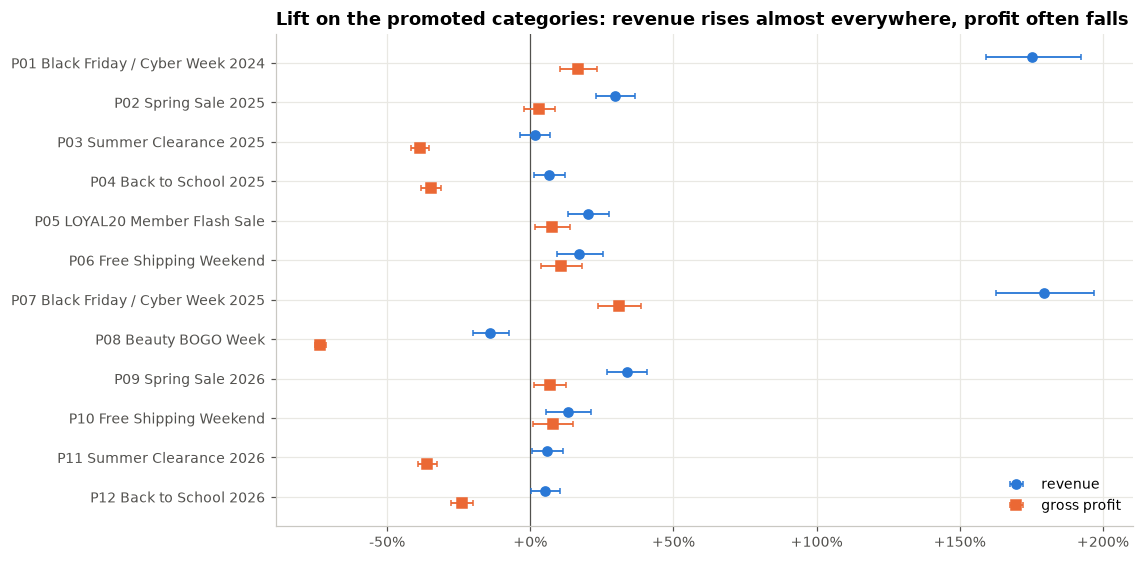

In [3]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
yy = np.arange(len(promo))[::-1]
ax.axvline(0, color=INK2, lw=0.8)
ax.errorbar(promo["revenue_lift"], yy + 0.16, xerr=[promo["revenue_lift"] - promo["revenue_lo"], promo["revenue_hi"] - promo["revenue_lift"]],
            fmt="o", color=BLUE, ecolor=BLUE, elinewidth=1.2, capsize=2, label="revenue")
ax.errorbar(promo["profit_lift"], yy - 0.16, xerr=[promo["profit_lift"] - promo["profit_lo"], promo["profit_hi"] - promo["profit_lift"]],
            fmt="s", color=ORANGE, ecolor=ORANGE, elinewidth=1.2, capsize=2, label="gross profit")
ax.set_yticks(yy); ax.set_yticklabels(promo["promo_id"] + " " + promo["name"].str.replace(r" \(.*\)", "", regex=True))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_title("Lift on the promoted categories: revenue rises almost everywhere, profit often falls")
ax.legend(loc="lower right")
save(fig, "03_promo_lift")

## A2. Black Friday: pull-forward and net effect

In [4]:
tot_rev, tot_prof = series(CATS, "revenue"), series(CATS, "profit")
net = []
for label, y in [("revenue", tot_rev), ("gross profit", tot_prof)]:
    b, se = fit(y)
    for yr, pid in (("2024", "P01"), ("2025", "P07")):
        a, e = day_index(PR.set_index("promo_id").loc[pid, "start_date"]), day_index(PR.set_index("promo_id").loc[pid, "end_date"])
        during = np.sum(y[a:e + 1] * (1 - np.exp(-b[pid])))
        pre = np.sum(y[max(a - 7, 0):a] * (1 - np.exp(-b["bf_pre7"])))
        post = np.sum(y[e + 1:e + 8] * (1 - np.exp(-b["bf_post7"])))
        net.append(dict(metric=label, year=yr, during=during, pre_week=pre, post_week=post, net=during + pre + post,
                        pulled_forward_share=-(pre + post) / during))
    z_pre, z_post = b["bf_pre7"] / se["bf_pre7"], b["bf_post7"] / se["bf_post7"]
    print(f"{label:12s}: week before {np.exp(b['bf_pre7']) - 1:+.1%} (p={2 * stats.norm.sf(abs(z_pre)):.4f}), "
          f"week after {np.exp(b['bf_post7']) - 1:+.1%} (p={2 * stats.norm.sf(abs(z_post)):.4f})")
net = pd.DataFrame(net)
net.to_csv(OUT / "promo_black_friday_net.csv", index=False)
display(net.assign(**{c: net[c].map("{:+,.0f}".format) for c in ["during", "pre_week", "post_week", "net"]},
                   pulled_forward_share=net["pulled_forward_share"].map("{:.0%}".format)))

revenue     : week before -5.9% (p=0.0006), week after -9.0% (p=0.0000)
gross profit: week before -5.7% (p=0.0003), week after -8.5% (p=0.0000)


,metric,year,during,pre_week,post_week,net,pulled_forward_share
0,revenue,2024,"+1,184,757","-67,263","-105,239","+1,012,255",15%
1,revenue,2025,"+1,452,166","-82,788","-128,714","+1,240,664",15%
2,gross profit,2024,"+41,317","-24,029","-36,676","-19,388",147%
3,gross profit,2025,"+98,376","-31,570","-46,988","+19,818",80%


## A3. Member-only flash sale (LOYAL20): who actually responded?
The code only works for loyalty members, so non-members are a natural control group.

In [5]:
O["member"] = S["is_loyalty_member"].values[O["session_id"].values - 1]
w0, w1 = ("2025-09-04", "2025-09-17"), ("2025-09-18", "2025-09-21")
cnt = lambda a, b, m: int(((O["day"].between(day_index(a), day_index(b))) & (O["member"] == m)).sum())
ses = lambda a, b, m: int(((S["day"].between(day_index(a), day_index(b))) & (S["is_loyalty_member"] == m)).sum())
res = {}
for m, lab in ((True, "members"), (False, "non-members")):
    r = two_prop(cnt(*w0, m), ses(*w0, m), cnt(*w1, m), ses(*w1, m))
    res[lab] = r
    print(f"{lab:12s} conversion {r['p1']:.2%} → {r['p2']:.2%}  ({r['lift']:+.1%} [{r['lift_lo']:+.1%}, {r['lift_hi']:+.1%}], p={fmt_p(r['p'])})")
lr = np.log(1 + res["members"]["lift"]) - np.log(1 + res["non-members"]["lift"])
print(f"member lift relative to non-members (DiD): {np.exp(lr) - 1:+.1%}")

members      conversion 6.97% → 8.94%  (+28.2% [+22.1%, +34.6%], p=1.49e-23)
non-members  conversion 4.49% → 4.69%  (+4.4% [+1.3%, +7.6%], p=0.0052)
member lift relative to non-members (DiD): +22.8%


**Promotion findings**

Two views matter and they can disagree: the **promoted categories** (does the discount pay for itself where it is applied?)
and the **whole store** (promotions are advertised, and the extra visitors also buy full-price items elsewhere).

* **Black Friday / Cyber Week** nearly triples revenue on the four days but adds only 17–31% to gross profit: a 25%
  sitewide discount all but wipes out the margin on Electronics (about half of revenue, ~25% margin). About 15% of the
  revenue lift is borrowed from the week before and the week after (both dips are significant); netted against that
  pull-forward, the **profit effect is roughly zero** (see A2). It is a revenue and customer-acquisition event, not a
  profit event — excluding or shallow-discounting thin-margin categories would change that.
* **Spring Sale** (15% off Fashion and Home & Garden) is the most profitable promotion on the calendar. In the promoted
  categories the discount roughly pays for itself (revenue +30–34%, profit about flat), and the traffic it brings lifts
  the rest of the store by 35–41% at full margin: store-wide profit +23–29%.
* **Summer Clearance** (30% off Fashion): Fashion units +50%, Fashion revenue barely moves and Fashion profit falls by
  more than a third. The halo on other categories offsets it, so store-wide profit is flat to slightly positive. The
  discount itself destroys margin; what earns money is the campaign traffic.
* **Back to School** (10% off Electronics and Books): a small revenue lift on thin margins costs a quarter to a third
  of the profit in those categories, and the halo is not enough to cover it — store-wide profit is flat to slightly
  negative. The weakest of the recurring promotions.
* **Beauty BOGO**: units jump mechanically, Beauty revenue *falls* and Beauty profit collapses by ~73%, with no halo
  (no extra traffic). There is no demand response at all — the offer gives away the second unit. Do not repeat it in
  this form.
* **Free shipping weekends**: revenue +13–17% and profit +8–11% even after counting the forgone shipping fees — the
  cheapest effective lever on the list.
* **LOYAL20**: member conversion up by over a quarter; non-members move only slightly (email traffic), so the
  difference-in-differences attributes most of the effect to the code rather than the calendar.
* No promotion cannibalises the rest of the store; where a "rest of store" effect exists it is a positive halo.

# Part B · A/B tests
## B1. AB1 — one-page checkout (2 Mar – 12 Apr 2026)
*Unit of randomisation:* user (50/50). *Primary metric (pre-registered in `ab_tests.csv`):* checkout → purchase conversion.
*Decision rule:* two-sided α = 0.05 on the primary metric; guardrails must not degrade.

Sessions, not users, are the unit of the primary metric, and a user's sessions are correlated. Treating sessions as
independent would understate the variance, so ratio metrics use the **delta method** on per-user totals.

In [6]:
T = S[S["ab_test"].eq("AB1_one_page_checkout")].copy()
T["treat"] = T["ab_variant"].eq("treatment").values
T["rev"] = 0.0
om = O.set_index("session_id")
has = T["purchased"].values
T.loc[has, "rev"] = om["revenue"].reindex(T.loc[has, "session_id"]).values
pu = T.groupby("user_id").agg(treat=("treat", "first"), sessions=("purchased", "size"), **{f: (f, "sum") for f in FLAGS}, revenue=("rev", "sum"))
pu["buyer"] = pu["purchased"] > 0
c, t = pu[~pu["treat"]], pu[pu["treat"]]
print(f"users: control {len(c):,}  treatment {len(t):,}   sessions: control {c['sessions'].sum():,}  treatment {t['sessions'].sum():,}")

# --- validity ---------------------------------------------------------------
srm = stats.chisquare([len(c), len(t)])
print(f"\nSample-ratio mismatch: chi2={srm.statistic:.2f}, p={srm.pvalue:.3f}  → {'OK (no SRM)' if srm.pvalue > 0.001 else 'SRM!'}")
Ux = U.set_index("user_id").loc[pu.index]
bal = []
for col in ["country", "age_group", "gender", "preferred_device", "acquisition_channel"]:
    chi2, p, dof, v = cramers_v(pd.crosstab(Ux[col], pu["treat"]).values)
    bal.append(dict(covariate=col, chi2=chi2, dof=dof, p=p, cramers_v=v))
pre_o = O[O["day"].between(day_index("2025-12-01"), day_index("2026-03-01"))].groupby("user_id")["revenue"].sum()
pu["pre_rev"] = pre_o.reindex(pu.index).fillna(0).values
tt = stats.ttest_ind(pu.loc[pu["treat"], "pre_rev"], pu.loc[~pu["treat"], "pre_rev"], equal_var=False)
bal.append(dict(covariate="revenue in the 90 days before the test", chi2=np.nan, dof=np.nan, p=tt.pvalue, cramers_v=np.nan))
print("Covariate balance (randomisation check — nothing should be significant):")
display(pd.DataFrame(bal))

users: control 436,071  treatment 435,242   sessions: control 766,987  treatment 763,121

Sample-ratio mismatch: chi2=0.79, p=0.374  → OK (no SRM)


Covariate balance (randomisation check — nothing should be significant):


,covariate,chi2,dof,p,cramers_v
0,country,4.4797,6.0000,0.6120,0.0023
1,age_group,7.5085,4.0000,0.1113,0.0029
2,gender,0.4889,2.0000,0.7831,0.0007
3,preferred_device,1.3014,2.0000,0.5217,0.0012
4,acquisition_channel,6.6315,5.0000,0.2495,0.0028
5,revenue in the 90 days before the test,NaN,NaN,0.7856,NaN


In [7]:
def ratio(num, den, cc=None, tt_=None):
    cc = c if cc is None else cc; tt_ = t if tt_ is None else tt_
    return ratio_delta(cc[num].values, cc[den].values, tt_[num].values, tt_[den].values)

def row(metric, r, kind):
    return dict(metric=metric, kind=kind, control=r["p1"], treatment=r["p2"], abs_diff=r["diff"], rel_lift=r["lift"],
                lift_lo=r["lift_lo"], lift_hi=r["lift_hi"], z=r["z"], p=r["p"])

res = []
res.append(row("checkout → purchase (PRIMARY)", ratio("purchased", "began_checkout"), "primary"))
res.append(row("  checkout → payment", ratio("entered_payment", "began_checkout"), "component"))
res.append(row("  payment → purchase", ratio("purchased", "entered_payment"), "component"))
res.append(row("visit → product view", ratio("viewed_product", "sessions"), "upstream sanity"))
res.append(row("view → add to cart", ratio("added_to_cart", "viewed_product"), "upstream sanity"))
res.append(row("cart → checkout", ratio("began_checkout", "added_to_cart"), "upstream sanity"))
res.append(row("session conversion (visit → purchase)", ratio("purchased", "sessions"), "secondary"))
res.append(row("user conversion (bought during test)", two_prop(c["buyer"].sum(), len(c), t["buyer"].sum(), len(t)), "secondary"))

def welch(a, b, name, kind):
    d = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return dict(metric=name, kind=kind, control=a.mean(), treatment=b.mean(), abs_diff=d, rel_lift=d / a.mean(),
                lift_lo=(d - 1.96 * se) / a.mean(), lift_hi=(d + 1.96 * se) / a.mean(), z=d / se, p=2 * stats.norm.sf(abs(d / se)))

res.append(welch(c["revenue"].values, t["revenue"].values, "revenue per user ($)", "secondary"))
# CUPED: remove the part of revenue explained by pre-period revenue
theta = np.cov(pu["revenue"], pu["pre_rev"])[0, 1] / pu["pre_rev"].var()
pu["rev_cuped"] = pu["revenue"] - theta * (pu["pre_rev"] - pu["pre_rev"].mean())
res.append(welch(pu.loc[~pu["treat"], "rev_cuped"].values, pu.loc[pu["treat"], "rev_cuped"].values, "revenue per user, CUPED-adjusted ($)", "secondary"))
var_red = 1 - pu["rev_cuped"].var() / pu["revenue"].var()

# guardrails (order level)
ot = O[O["session_id"].isin(T["session_id"])].copy()
ot["treat"] = T.set_index("session_id")["treat"].reindex(ot["session_id"]).values
oc, otr = ot[~ot["treat"]], ot[ot["treat"]]
res.append(welch(oc["revenue"].values, otr["revenue"].values, "average order value ($)", "guardrail"))
res.append(row("cancellation rate", two_prop((oc["status"] == "cancelled").sum(), len(oc), (otr["status"] == "cancelled").sum(), len(otr)), "guardrail"))
res.append(row("orders with a return", two_prop(oc["status"].isin(["returned", "partially_returned"]).sum(), len(oc),
                                                otr["status"].isin(["returned", "partially_returned"]).sum(), len(otr)), "guardrail"))
ab1 = pd.DataFrame(res)
ab1["sig"] = ab1["p"].map(stars)
ab1.to_csv(OUT / "ab1_results.csv", index=False)
fm = ab1.copy()
isd = fm["metric"].str.contains(r"\$")
for col in ["control", "treatment"]:
    fm[col] = np.where(isd, ab1[col].map("{:,.2f}".format), ab1[col].map("{:.2%}".format))
fm["relative lift (95% CI)"] = ab1.apply(lambda r: f"{r.rel_lift:+.2%} [{r.lift_lo:+.2%}, {r.lift_hi:+.2%}]", axis=1)
fm["p"] = ab1["p"].map(fmt_p)
display(fm[["metric", "kind", "control", "treatment", "relative lift (95% CI)", "z", "p", "sig"]])
print(f"CUPED variance reduction on revenue per user: {var_red:.1%} (theta = {theta:.3f})")

# bootstrap check of the revenue-per-user CI (heavy-tailed metric)
rng = np.random.default_rng(7)
cv, tv = c["revenue"].values, t["revenue"].values
boot = np.array([tv[rng.integers(0, len(tv), len(tv))].mean() - cv[rng.integers(0, len(cv), len(cv))].mean() for _ in range(400)])
print(f"revenue per user difference: ${tv.mean() - cv.mean():+.3f}; bootstrap 95% CI [{np.percentile(boot, 2.5):+.3f}, {np.percentile(boot, 97.5):+.3f}] "
      f"(matches the Welch interval → the normal approximation is adequate at this n)")

# naive (wrong) analysis for comparison: sessions treated as independent
k = T.groupby("treat")[["began_checkout", "purchased"]].sum()
naive = two_prop(k.loc[False, "purchased"], k.loc[False, "began_checkout"], k.loc[True, "purchased"], k.loc[True, "began_checkout"])
prim = ratio("purchased", "began_checkout")
print(f"primary metric SE: delta method {prim['se']:.5f} vs naive session-level {(naive['diff_hi'] - naive['diff_lo']) / 3.92:.5f} "
      f"(ratio {prim['se'] / ((naive['diff_hi'] - naive['diff_lo']) / 3.92):.3f})")
k2 = T.groupby("treat")["purchased"].agg(["sum", "size"])
n2 = two_prop(k2.loc[False, "sum"], k2.loc[False, "size"], k2.loc[True, "sum"], k2.loc[True, "size"])
sc = ratio("purchased", "sessions")
print(f"session conversion SE:  delta method {sc['se']:.6f} vs naive {(n2['diff_hi'] - n2['diff_lo']) / 3.92:.6f} "
      f"(ratio {sc['se'] / ((n2['diff_hi'] - n2['diff_lo']) / 3.92):.3f}) — the naive SE is too small wherever users have several sessions")

,metric,kind,control,treatment,relative lift (95% CI),z,p,sig
0,checkout → purchase (PRIMARY),primary,64.41%,65.74%,"+2.07% [+1.21%, +2.94%]",4.7349,2.19e-06,***
1,checkout → payment,component,75.24%,76.43%,"+1.59% [+0.92%, +2.25%]",4.7128,2.44e-06,***
2,payment → purchase,component,85.61%,86.02%,"+0.48% [-0.07%, +1.02%]",1.7212,0.0852,ns
3,visit → product view,upstream sanity,65.00%,65.04%,"+0.07% [-0.17%, +0.30%]",0.5725,0.5670,ns
4,view → add to cart,upstream sanity,20.04%,20.08%,"+0.19% [-0.63%, +1.01%]",0.4547,0.6493,ns
5,cart → checkout,upstream sanity,57.32%,57.22%,"-0.18% [-0.94%, +0.58%]",-0.4649,0.6420,ns
6,session conversion (visit → purchase),secondary,4.81%,4.91%,"+2.15% [+0.68%, +3.62%]",2.9035,0.0037,**
7,user conversion (bought during test),secondary,7.89%,8.04%,"+1.89% [+0.45%, +3.36%]",2.5722,0.0101,*
8,revenue per user ($),secondary,9.39,9.52,"+1.34% [-1.27%, +3.95%]",1.0069,0.3140,ns
9,"revenue per user, CUPED-adjusted ($)",secondary,9.39,9.51,"+1.32% [-1.28%, +3.93%]",0.9966,0.3190,ns


CUPED variance reduction on revenue per user: 0.2% (theta = 0.036)


revenue per user difference: $+0.126; bootstrap 95% CI [-0.142, +0.368] (matches the Welch interval → the normal approximation is adequate at this n)
primary metric SE: delta method 0.00282 vs naive session-level 0.00282 (ratio 1.000)
session conversion SE:  delta method 0.000357 vs naive 0.000348 (ratio 1.025) — the naive SE is too small wherever users have several sessions


### Heterogeneity: does the effect depend on the segment?
Segment cuts are exploratory, so p-values are BH-adjusted across all of them. The formal question for device is an
**interaction test**: is the mobile lift different from the desktop lift?

,dimension,segment,users,denom,control,treatment,rel_lift,lift_lo,lift_hi,p,p_adj,sig_raw,sig_adj
0,device,desktop,51331,56214,0.7080,0.7037,-0.0060,-0.0166,0.0046,0.2667,0.2808,ns,ns
1,device,mobile,46267,49665,0.5753,0.6052,0.0519,0.0365,0.0673,1.17e-11,2.33e-10,***,***
2,device,tablet,7924,8431,0.6251,0.6553,0.0483,0.0146,0.0819,0.0040,0.0113,**,*
3,user_type,new,8777,8777,0.6188,0.6529,0.0550,0.0216,0.0885,9.15e-04,0.0037,***,**
4,user_type,returning,95452,105533,0.6462,0.6578,0.0180,0.0091,0.0270,7.03e-05,3.52e-04,***,***
5,loyalty,member,25260,28917,0.6435,0.6537,0.0158,-0.0015,0.0331,0.0705,0.1175,ns,ns
6,loyalty,non-member,78541,85393,0.6443,0.6587,0.0224,0.0124,0.0324,9.21e-06,9.21e-05,***,***
7,channel,Organic Search,29006,29858,0.6465,0.6602,0.0212,0.0043,0.0381,0.0127,0.0283,*,*
8,channel,Paid Search,22398,22905,0.6412,0.6519,0.0167,-0.0028,0.0362,0.0912,0.1216,ns,ns
9,channel,Direct,23465,24063,0.6417,0.6523,0.0166,-0.0024,0.0356,0.0838,0.1198,ns,ns


Heterogeneity of the lift within each dimension (Cochran's Q, BH-adjusted across the 5 dimensions):


,dimension,levels,Q,p,p_adj,sig_adj
0,device,3,40.9444,0.0000,0.0000,***
1,user_type,2,4.3798,0.0364,0.0667,ns
2,loyalty,2,0.4186,0.5176,0.6470,ns
3,channel,6,3.3108,0.6522,0.6522,ns
4,country,7,13.1966,0.0400,0.0667,ns


interaction (mobile lift − desktop lift): +5.80% pts, z=6.08, p=1.24e-09


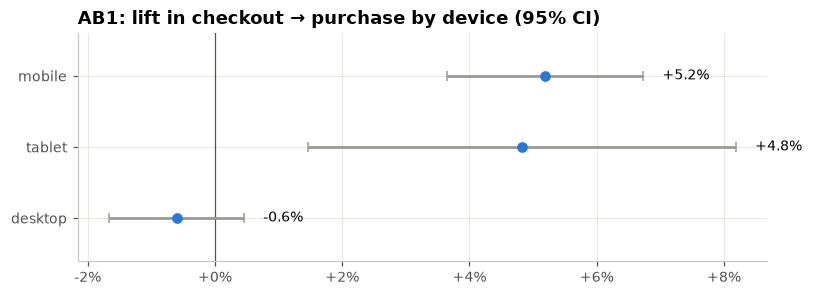

In [8]:
def seg_effects(test_df, dims, num, den):
    out = []
    for dim in dims:
        g = test_df.groupby(["user_id", dim], observed=True).agg(treat=("treat", "first"), n=(num, "sum"), d=(den, "sum")).reset_index()
        for lvl, gg in g.groupby(dim, observed=True):
            gg = gg[gg["d"] > 0] if den != "sessions" else gg
            a, b = gg[~gg["treat"]], gg[gg["treat"]]
            r = ratio_delta(a["n"].values, a["d"].values, b["n"].values, b["d"].values)
            out.append(dict(dimension=dim, segment=str(lvl), users=len(gg), denom=int(gg["d"].sum()), control=r["p1"], treatment=r["p2"],
                            rel_lift=r["lift"], lift_lo=r["lift_lo"], lift_hi=r["lift_hi"], p=r["p"], _se=(r["lift_hi"] - r["lift_lo"]) / 3.92))
    out = pd.DataFrame(out)
    out["p_adj"] = bh(out["p"]); out["sig_raw"] = out["p"].map(stars); out["sig_adj"] = out["p_adj"].map(stars)
    return out

T["sessions"] = 1
# raw counts for the Excel workbook (which recomputes the tests with live formulas)
cnt1 = T.groupby(["ab_variant", "device"], observed=True)[STAGES].sum().reset_index()
cnt1.insert(0, "ab_test", "AB1_one_page_checkout")
cnt1["users"] = T.groupby(["ab_variant", "device"], observed=True)["user_id"].nunique().values
cnt1.to_csv(OUT / "ab1_counts.csv", index=False)
pd.DataFrame({"ab_variant": ["control", "treatment"], "users": [len(c), len(t)], "buyers": [c["buyer"].sum(), t["buyer"].sum()],
              "revenue": [c["revenue"].sum(), t["revenue"].sum()], "revenue_sd": [c["revenue"].std(), t["revenue"].std()]}).to_csv(OUT / "ab1_users.csv", index=False)
T["user_type"] = np.where(T["is_new_user"], "new", "returning")
T["loyalty"] = np.where(T["is_loyalty_member"], "member", "non-member")
seg1 = seg_effects(T, ["device", "user_type", "loyalty", "channel", "country"], "purchased", "began_checkout")
seg1.drop(columns="_se").to_csv(OUT / "ab1_segments.csv", index=False)
display(seg1.drop(columns="_se").assign(p=seg1["p"].map(fmt_p), p_adj=seg1["p_adj"].map(fmt_p)))

# Is the lift DIFFERENT across the levels of a dimension? (Cochran's Q; a significant segment is not the same thing as
# a segment that differs from the rest — every segment contains mobile users and so inherits part of the real effect.)
het = []
for dim, gdf in seg1.groupby("dimension", sort=False):
    w = 1 / gdf["_se"] ** 2
    lbar = np.sum(w * gdf["rel_lift"]) / w.sum()
    Q = float(np.sum(w * (gdf["rel_lift"] - lbar) ** 2))
    het.append(dict(dimension=dim, levels=len(gdf), Q=Q, p=stats.chi2.sf(Q, len(gdf) - 1)))
het = pd.DataFrame(het); het["p_adj"] = bh(het["p"]); het["sig_adj"] = het["p_adj"].map(stars)
het.to_csv(OUT / "ab1_heterogeneity.csv", index=False)
print("Heterogeneity of the lift within each dimension (Cochran's Q, BH-adjusted across the 5 dimensions):")
display(het)
d = seg1[seg1["dimension"].eq("device")].set_index("segment")
zi =(d.loc["mobile", "rel_lift"] - d.loc["desktop", "rel_lift"]) / np.hypot(d.loc["mobile", "_se"], d.loc["desktop", "_se"])
print(f"interaction (mobile lift − desktop lift): {d.loc['mobile', 'rel_lift'] - d.loc['desktop', 'rel_lift']:+.2%} pts, z={zi:.2f}, p={fmt_p(2 * stats.norm.sf(abs(zi)))}")

fig, ax = plt.subplots(figsize=(7.5, 2.8))
dd = d.loc[["desktop", "tablet", "mobile"]]
ax.axvline(0, color=INK2, lw=0.8)
ax.errorbar(dd["rel_lift"], range(3), xerr=[dd["rel_lift"] - dd["lift_lo"], dd["lift_hi"] - dd["rel_lift"]], fmt="o",
            color=BLUE, ecolor=GREY, capsize=3)
for i, (s_, r) in enumerate(dd.iterrows()):
    ax.text(r["lift_hi"] + 0.003, i, f"{r['rel_lift']:+.1%}", va="center", fontsize=9)
ax.set_yticks(range(3)); ax.set_yticklabels(dd.index); ax.set_ylim(-0.6, 2.6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_title("AB1: lift in checkout → purchase by device (95% CI)")
save(fig, "03_ab1_by_device")

### Peeking and power
The cumulative z-statistic is shown for every day of the test. Stopping the first time it crosses 1.96 inflates the
false-positive rate; the O'Brien–Fleming boundary shows what an early look would have needed.

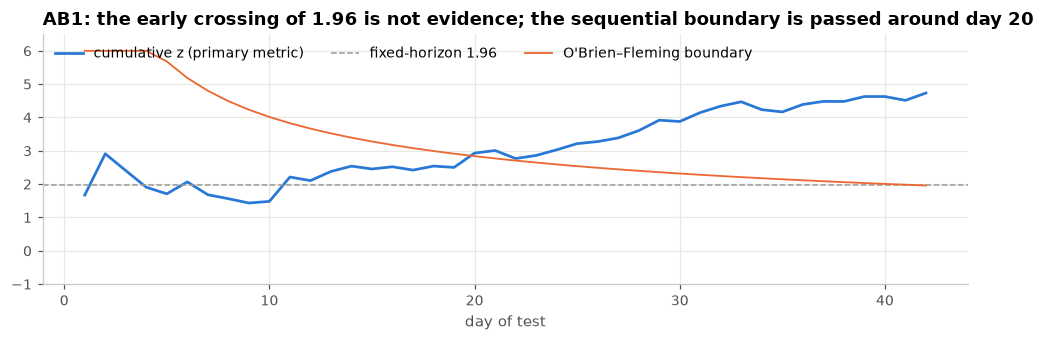

z first exceeds 1.96 on day 2; crosses the O'Brien–Fleming boundary on day 20; final z = 4.73
Minimum detectable effect at 80% power, primary metric: 1.23% relative (observed +2.07%)
Minimum detectable effect at 80% power, user conversion:  2.06% relative (observed +1.89%) → power for the observed effect = 73%
Projected impact of rolling out on mobile: 436,332 mobile checkouts/yr × 57.5% × +5.2% ≈ 13,034 extra orders ≈ $1,480,666/yr (95% CI $1,041,645 – $1,919,687)


In [9]:
T["tday"] = T["day"] - T["day"].min()
days_ = np.arange(T["tday"].max() + 1)
zs = []
for dday in days_:
    sub = T[T["tday"] <= dday].groupby("user_id").agg(treat=("treat", "first"), n=("purchased", "sum"), d=("began_checkout", "sum"))
    r = ratio_delta(sub.loc[~sub["treat"], "n"].values, sub.loc[~sub["treat"], "d"].values, sub.loc[sub["treat"], "n"].values, sub.loc[sub["treat"], "d"].values)
    zs.append((dday + 1, r["z"], r["lift"], r["lift_lo"], r["lift_hi"]))
peek = pd.DataFrame(zs, columns=["day", "z", "lift", "lo", "hi"])
peek["obf_bound"] = 1.96 / np.sqrt(peek["day"] / peek["day"].max())
peek.to_csv(OUT / "ab1_daily_cumulative.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(peek["day"], peek["z"], color=BLUE, label="cumulative z (primary metric)")
ax.axhline(1.96, color=GREY, ls="--", lw=1, label="fixed-horizon 1.96")
ax.plot(peek["day"], peek["obf_bound"].clip(upper=6), color=ORANGE, lw=1.2, label="O'Brien–Fleming boundary")
ax.set_xlabel("day of test"); ax.set_ylim(-1, 6.5); ax.legend(ncol=3, loc="upper left")
ax.set_title("AB1: the early crossing of 1.96 is not evidence; the sequential boundary is passed around day 20")
save(fig, "03_ab1_peeking")
first = peek.loc[peek["z"] > peek["obf_bound"], "day"].min()
print(f"z first exceeds 1.96 on day {peek.loc[peek['z'] > 1.96, 'day'].min()}; crosses the O'Brien–Fleming boundary on day {first}; final z = {peek['z'].iloc[-1]:.2f}")

se_p = prim["se"]
mde = (1.96 + 0.84) * se_p / prim["p1"]
uc = two_prop(c["buyer"].sum(), len(c), t["buyer"].sum(), len(t))
se_u = (uc["diff_hi"] - uc["diff_lo"]) / 3.92
print(f"Minimum detectable effect at 80% power, primary metric: {mde:.2%} relative (observed {prim['lift']:+.2%})")
print(f"Minimum detectable effect at 80% power, user conversion:  {(1.96 + 0.84) * se_u / uc['p1']:.2%} relative (observed {uc['lift']:+.2%}) "
      f"→ power for the observed effect = {stats.norm.sf(1.96 - abs(uc['diff']) / se_u):.0%}")
yr_chk = S[(S["day"] >= day_index("2025-11-01")) & S["began_checkout"] & S["device"].eq("mobile")].shape[0]
mob = d.loc["mobile"]
aov_m = O.loc[O["device"].eq("mobile"), "revenue"].mean()
print(f"Projected impact of rolling out on mobile: {yr_chk:,} mobile checkouts/yr × {mob['control']:.1%} × {mob['rel_lift']:+.1%} "
      f"≈ {yr_chk * mob['control'] * mob['rel_lift']:,.0f} extra orders ≈ ${yr_chk * mob['control'] * mob['rel_lift'] * aov_m:,.0f}/yr "
      f"(95% CI ${yr_chk * mob['control'] * mob['lift_lo'] * aov_m:,.0f} – ${yr_chk * mob['control'] * mob['lift_hi'] * aov_m:,.0f})")

**AB1 conclusion — ship it (on mobile and tablet).**

* Validity: no sample-ratio mismatch, covariates balanced, and the three funnel steps *before* checkout are identical
  between arms — as they must be, since the treatment only changes the checkout page.
* Primary metric: checkout → purchase improves by about 2% relative (z ≈ 4.7); most of it comes from
  checkout → payment, the step the redesign targeted.
* Heterogeneity: the lift is ~5% on mobile and tablet and **zero on desktop**; the mobile–desktop interaction is highly
  significant, so this is a real difference in effect, not a subgroup accident. Several other segments (new users,
  Social, DE, FR) are individually "significant" even after BH — but that only says the overall effect is real and
  they contain many mobile users. The heterogeneity test is the right tool: read the Cochran's Q table above to see
  which dimensions genuinely differ, and treat anything other than device as a hypothesis for a follow-up test.
* Secondary metrics dilute the same effect across all visitors: session and user conversion are up ~2% (significant),
  revenue per user is up ~1.3% but **not significant** — spend is far noisier than conversion, and the test was sized
  for the primary metric. CUPED does not help here (pre-period revenue explains under 1% of the variance because
  purchases are infrequent); it is reported so the null gain is visible rather than assumed.
* Peeking: the z-statistic first passed 1.96 on day 2 — stopping then would have been luck, not evidence. It crosses
  the O'Brien–Fleming boundary around day 20 and stays above it.
* Guardrails: AOV, cancellations and returns are unchanged.
* The post-rollout before/after comparison in notebook 02 (mobile vs desktop DiD) reproduces the experiment's estimate.

## B2. AB2 — social-proof badge (7 Sep – 4 Oct 2026)
Primary metric: product view → add to cart.

users: control 358,917 treatment 358,542; SRM chi2=0.20, p=0.658


,metric,kind,control,treatment,relative lift (95% CI),z,p,sig
0,view → add to cart (PRIMARY),primary,20.38%,20.40%,"+0.07% [-0.90%, +1.04%]",0.1382,0.8901,ns
1,session conversion,secondary,4.90%,4.96%,"+1.26% [-0.48%, +2.99%]",1.4307,0.1525,ns
2,visit → product view,upstream sanity,64.62%,64.67%,"+0.08% [-0.21%, +0.37%]",0.5442,0.5863,ns


MDE at 80% power: 1.38% relative → any effect larger than that would very likely have been seen



Segment scan: 20 segments; raw p < 0.05 in 0; after BH adjustment: 0. Expected false positives at α=0.05 under the null: 1.0


,dimension,segment,users,denom,control,treatment,rel_lift,lift_lo,lift_hi,p,p_adj,sig_raw,sig_adj
16,country,CA,45448,59478,0.2028,0.1982,-0.0228,-0.0548,0.0092,0.1666,0.9688,ns,ns
3,user_type,new,78538,78538,0.1380,0.1353,-0.0196,-0.0541,0.0149,0.2699,0.9688,ns,ns
15,country,DE,60795,79513,0.2127,0.2097,-0.0141,-0.0412,0.0131,0.3127,0.9688,ns,ns
18,country,AU,30476,39840,0.1930,0.1970,0.0206,-0.0210,0.0621,0.3267,0.9688,ns,ns
17,country,FR,40747,53440,0.1923,0.1956,0.0171,-0.0188,0.0531,0.3466,0.9688,ns,ns
7,channel,Organic Search,165884,181925,0.1934,0.1944,0.0052,-0.0138,0.0241,0.5905,0.9688,ns,ns


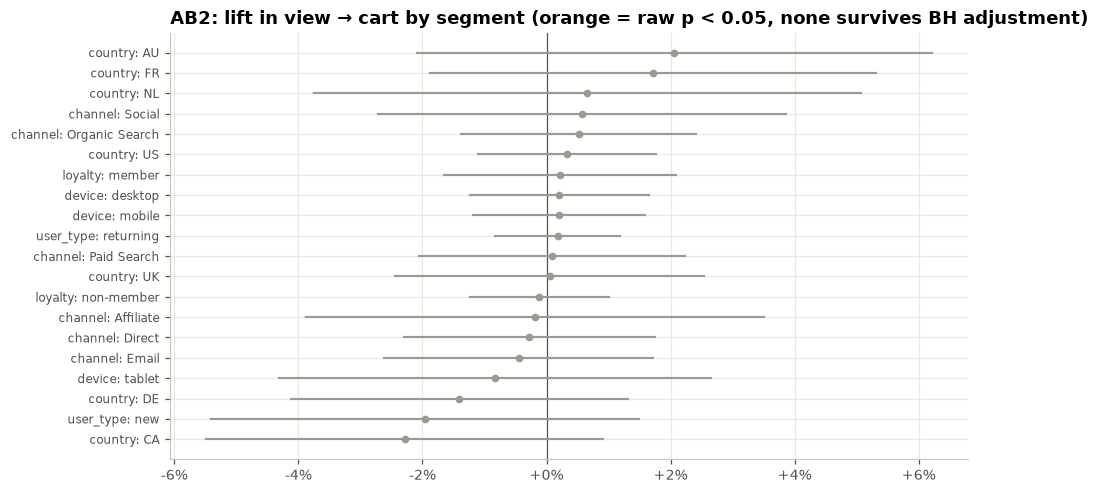

In [10]:
T2 = S[S["ab_test"].eq("AB2_social_proof_badge")].copy()
T2["treat"] = T2["ab_variant"].eq("treatment").values
T2["sessions"] = 1
T2["user_type"] = np.where(T2["is_new_user"], "new", "returning")
T2["loyalty"] = np.where(T2["is_loyalty_member"], "member", "non-member")
cnt2 = T2.groupby(["ab_variant", "device"], observed=True)[STAGES].sum().reset_index()
cnt2.insert(0, "ab_test", "AB2_social_proof_badge")
cnt2["users"] = T2.groupby(["ab_variant", "device"], observed=True)["user_id"].nunique().values
cnt2.to_csv(OUT / "ab2_counts.csv", index=False)
p2 = T2.groupby("user_id").agg(treat=("treat", "first"), sessions=("purchased", "size"), **{f: (f, "sum") for f in FLAGS})
c2, t2 = p2[~p2["treat"]], p2[p2["treat"]]
srm2 = stats.chisquare([len(c2), len(t2)])
print(f"users: control {len(c2):,} treatment {len(t2):,}; SRM chi2={srm2.statistic:.2f}, p={srm2.pvalue:.3f}")
r2 = [row("view → add to cart (PRIMARY)", ratio("added_to_cart", "viewed_product", c2, t2), "primary"),
      row("session conversion", ratio("purchased", "sessions", c2, t2), "secondary"),
      row("visit → product view", ratio("viewed_product", "sessions", c2, t2), "upstream sanity")]
ab2 = pd.DataFrame(r2); ab2["sig"] = ab2["p"].map(stars)
ab2.to_csv(OUT / "ab2_results.csv", index=False)
display(ab2.assign(control=ab2["control"].map("{:.2%}".format), treatment=ab2["treatment"].map("{:.2%}".format),
                   **{"relative lift (95% CI)": ab2.apply(lambda r: f"{r.rel_lift:+.2%} [{r.lift_lo:+.2%}, {r.lift_hi:+.2%}]", axis=1)})
        [["metric", "kind", "control", "treatment", "relative lift (95% CI)", "z", "p", "sig"]])
pr2 = ratio("added_to_cart", "viewed_product", c2, t2)
print(f"MDE at 80% power: {(1.96 + 0.84) * pr2['se'] / pr2['p1']:.2%} relative → any effect larger than that would very likely have been seen")

seg2 = seg_effects(T2, ["device", "user_type", "loyalty", "channel", "country"], "added_to_cart", "viewed_product")
seg2.drop(columns="_se").to_csv(OUT / "ab2_segments.csv", index=False)
n_raw, n_adj = (seg2["p"] < 0.05).sum(), (seg2["p_adj"] < 0.05).sum()
print(f"\nSegment scan: {len(seg2)} segments; raw p < 0.05 in {n_raw}; after BH adjustment: {n_adj}. "
      f"Expected false positives at α=0.05 under the null: {len(seg2) * 0.05:.1f}")
display(seg2.sort_values("p").head(6).drop(columns="_se"))

fig, ax = plt.subplots(figsize=(9, 4.6))
s2 = seg2.sort_values("rel_lift").reset_index(drop=True)
col = [ORANGE if p < 0.05 else GREY for p in s2["p"]]
ax.axvline(0, color=INK2, lw=0.8)
for i, r in s2.iterrows():
    ax.plot([r["lift_lo"], r["lift_hi"]], [i, i], color=col[i], lw=1.4)
    ax.plot(r["rel_lift"], i, "o", color=col[i], ms=4)
ax.set_yticks(range(len(s2))); ax.set_yticklabels(s2["dimension"] + ": " + s2["segment"], fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_title("AB2: lift in view → cart by segment (orange = raw p < 0.05, none survives BH adjustment)" if n_adj == 0
             else "AB2: lift in view → cart by segment (orange = raw p < 0.05)")
save(fig, "03_ab2_segments")

**AB2 conclusion — no effect; do not ship on this evidence.**

The primary metric is flat with a tight confidence interval: the test was large enough to detect a lift of about 1%, so
this is evidence of *absence*, not an under-powered shrug. A scan of 20 segments finds nothing either (chance alone would
be expected to produce about one raw p < 0.05; see the printed count), and nothing survives Benjamini–Hochberg
adjustment. Reporting the best-looking segment from such a scan is the most common way a null experiment turns into a
shipped feature.